# Comparación EfficientNet-B4 vs ViT-B/16 (versión 4, con partición por escena)
### Clasificación de imágenes reales vs. generadas por IA — `Defactify_Image_Dataset`
### Framework: PyTorch Lightning

Este notebook entrena y compara dos arquitecturas sobre la misma tarea binaria (real vs. generada por IA):

- **CNN**: EfficientNet-B4 (pre-entrenado en ImageNet, vía `timm`)
- **Transformer**: ViT-B/16 (pre-entrenado en ImageNet, vía `timm`)

**Métricas comparadas**: AUROC, accuracy y accuracy balanceada, precisión, recall, F1 (de la clase IA y de la clase real),
matriz de confusión, intervalos de confianza por bootstrap, McNemar, número de parámetros,
tiempo de entrenamiento y latencia de inferencia.

#### Qué cambió respecto a la versión 3

La versión 3 (`comparacion_efficientnet_vit3.ipynb`) queda como registro de las cifras reportadas hasta ahora.
Esta versión corrige problemas que podían inflar o sesgar los resultados:

1. **Fuga por escena en la validación cruzada.** En Defactify cada caption de COCO tiene una foto real y cinco
   imágenes sintéticas hechas con ese mismo texto. La CV usaba `StratifiedKFold` sobre imágenes sueltas, así que las
   "hermanas" de una escena quedaban repartidas entre entrenamiento y evaluación. Ahora se usa `StratifiedGroupKFold`
   con el caption normalizado como grupo.
2. **Escenas compartidas entre los splits oficiales.** Los splits de Hugging Face comparten unos pocos captions
   (25 train∩val, 31 train∩test, 7 val∩test según el EDA). Esas imágenes se quitan de validación y test.
3. **Dataset completo.** Se quitó `fast_dev_mode`: se entrena con todo el train y se evalúa con todo el test.
4. **La CV evaluaba en el mismo fold que usaba para parar y elegir el checkpoint.** Ahora cada fold separa una
   validación interna (también por escena) para el `EarlyStopping`, el checkpoint y el umbral, y reporta en el fold
   que el modelo nunca vio.
5. **Deformación de las fotos reales.** `Resize((s, s))` estiraba las fotos reales (casi nunca cuadradas) y dejaba
   intactas las sintéticas (todas cuadradas): la deformación era una pista de la clase. Ahora se redimensiona por el
   lado corto y se recorta al centro, conservando la proporción.
6. **Umbral fijo en 0.5.** El ViT entrena con `pos_weight`, lo que desplaza sus probabilidades; comparar ambos con 0.5
   lo perjudica en recall. El umbral se elige ahora en validación (máximo F1) y se reportan las dos versiones.
7. **Selección del modelo guardado con el test.** Se elegía por `test_f1`. Ahora se elige por AUROC de validación.
8. **Semillas.** Cada entrenamiento fija su semilla al empezar, así el resultado no depende del orden de las celdas.
9. **Comparación estadística.** Se agrega el t pareado corregido de Nadeau y Bengio para la CV, bootstrap por escena
   y McNemar en el test. Las predicciones se guardan en CSV.
10. **Latencia** medida con el mismo tamaño de batch para los dos modelos.

Las cifras de la versión 3 **no son comparables** con las de esta versión: hay que volver a correr todo y actualizar el documento.

#### Cómo ejecutarlo

- **Necesita GPU.** En Colab: *Entorno de ejecución → Cambiar tipo de entorno → GPU (L4 o A100)* y luego
  *Ejecutar todas*. En CPU no es viable (entrenar EfficientNet-B4 tomaría días), así que el notebook se detiene si no encuentra GPU.
- **Duración aproximada con el dataset completo**: 6 a 8 horas en una L4, unas 3 a 4 en una A100. La mayor parte es la validación cruzada.
- **Resultados en Google Drive.** Cada etapa (cada modelo y cada fold de la CV) guarda su resultado en
  `MyDrive/tesis_deteccion_ia_v4/`. Si Colab se desconecta, vuelve a *Ejecutar todas*: las etapas terminadas se cargan
  desde Drive y solo se entrena lo que falta. Si cambias la configuración, las etapas afectadas se reentrenan solas.

In [1]:
# Instalación de dependencias (Colab-friendly)
!pip install -q lightning timm datasets torchmetrics scikit-learn matplotlib seaborn pandas statsmodels

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 46.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 87.1 MB/s eta 0:00:00


In [2]:
import os
import json
import shutil
import re
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

import lightning as L
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint, LearningRateMonitor
from lightning.pytorch.loggers import CSVLogger

import timm
from torchvision import transforms
from torchvision.transforms import InterpolationMode

from datasets import load_dataset

from torchmetrics.classification import (
    BinaryAccuracy, BinaryPrecision, BinaryRecall, BinaryF1Score,
    BinaryAUROC, BinaryConfusionMatrix
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, precision_recall_curve
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
L.seed_everything(SEED, workers=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Usando device: {DEVICE}")
if DEVICE != "cuda":
    raise RuntimeError(
        "No hay GPU. Este notebook entrena con el dataset completo y en CPU tardaría días. "
        "En Colab: Entorno de ejecución -> Cambiar tipo de entorno de ejecución -> GPU (L4 o A100)."
    )
print(torch.cuda.get_device_name(0))

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


Usando device: cuda
NVIDIA RTX PRO 6000 Blackwell Server Edition


## 1. Configuración

Ajusta aquí los hiperparámetros. Mantén `max_epochs`, `lr`, `weight_decay` y `batch_size_effective`
iguales entre ambos modelos para que la comparación sea justa — solo cambian la resolución de imagen
(cada arquitectura fue pre-entrenada con un tamaño distinto) y el batch físico, que se compensa
con `accumulate_grad_batches` para que el batch efectivo sea el mismo.

**Sobre EarlyStopping y tiempos largos por época:**
- `val_check_interval=0.25` hace que Lightning valide 4 veces por época (no solo al final), así el `EarlyStopping` puede cortar el entrenamiento **a mitad de una época** si no hay mejora — no tienes que esperar a que termine completa para que actúe.

**Receta propia del ViT.** El primer intento del ViT con la receta compartida (lr 3e-4, sin warmup ni pesos de clase, paciencia de 3 validaciones)
colapsó a "todo IA" (AUROC 0.57). Los transformers son mucho más sensibles al lr que las CNN, así que en `CONFIG["vit"]`
se sobreescriben `lr`, `warmup_ratio`, `use_pos_weight`, `grad_clip` y la paciencia. EfficientNet-B4 sigue con la receta original.
La normalización de cada modelo se toma ahora de `timm` (`resolve_data_config`) en lugar de fijarla a mano.
El ViT también monitorea `val_auroc` (no `val_f1`) para el EarlyStopping y el checkpoint: con clases desbalanceadas, el F1 de un clasificador trivial ya es ~0.90 y no distingue un modelo que colapsó de uno que está aprendiendo.


**Partición por escena.** Todas las particiones (limpieza de los splits oficiales y folds de la CV) se
hacen por escena, usando el `Caption` normalizado como grupo. Así una foto real y sus cinco versiones sintéticas
siempre quedan juntas en el mismo conjunto.

**Umbral.** Con `tune_threshold_on_val=True` el umbral de decisión de cada modelo se elige en validación (máximo F1)
y se aplica al test sin tocarlo. Siempre se reportan también las métricas con 0.5.

In [3]:
CONFIG = {
    # Datos
    "dataset_name": "Rajarshi-Roy-research/Defactify_Image_Dataset",
    "num_classes": 2,                 # informativo (real vs generada por IA). No se usa: la cabeza tiene 1 logit, ver ImageClassifierModule
    "val_fraction": 0.1,              # si el dataset no trae split de validación, se separa del train
    "num_workers": min(10, os.cpu_count() or 2),  # procesos que decodifican imágenes (la CPU suele ser el cuello de botella)
    "caption_col": "Caption",         # se usa como grupo de escena: 1 foto real + 5 sintéticas con el mismo caption

    # --- Evaluación ---
    "tune_threshold_on_val": True,    # umbral = máximo F1 en validación (además se reportan las métricas con 0.5)
    "latency_batch_size": 32,         # mismo batch para medir la latencia de los dos modelos
    "n_bootstrap": 1000,              # remuestreos (por escena) para los intervalos de confianza del test

    # Entrenamiento (mismo presupuesto para ambos modelos -> comparación justa)
    "max_epochs": 10,
    "lr": 3e-4,
    "weight_decay": 1e-4,
    "batch_size_effective": 64,       # batch size lógico (se ajusta con accumulate_grad_batches si hace falta)
    "precision": "16-mixed",          # mixed precision si hay GPU compatible

    # --- EarlyStopping ---
    "patience_early_stop": 3,         # nº de validaciones (no necesariamente épocas) sin mejora antes de parar
    "val_check_interval": 0.25,       # valida 4 veces por época (cada 25% de los batches de train)
                                       # -> el EarlyStopping puede cortar A MITAD de una época, no solo al final
    "min_delta_early_stop": 0.001,    # mejora mínima en la métrica monitoreada (por defecto val_f1; cfg["monitor"] la cambia por modelo)

    # --- Cross-validation (k-fold estratificado) ---
    # Se entrena el modelo n_splits veces (una por fold) -> multiplica el tiempo total.
    # Por eso usa un presupuesto de épocas más chico que el entrenamiento final.
    "cross_validation": {
        "n_splits": 5,
        "max_epochs": 5,          # menor que CONFIG["max_epochs"] a propósito
        "patience_early_stop": 2, # más agresivo, ya que cada fold es más barato
    },

    # --- Mapeo de etiquetas (confirmado: 0 = Real, 1 = Falso/Generada por IA) ---
    "label_mapping": {0: "Real", 1: "Falso"},

    # Modelos (timm)
    "efficientnet": {
        "model_name": "efficientnet_b4",
        "image_size": 380,            # resolución nativa de EfficientNet-B4
        "batch_size": 32,             # batch físico (menor por mayor uso de memoria a 380x380)
    },
    "vit": {
        "model_name": "vit_base_patch16_224",
        "image_size": 224,            # resolución nativa de ViT-B/16
        "batch_size": 64,

        # --- Receta propia del ViT (la compartida, lr 3e-4 sin warmup, lo hizo colapsar) ---
        "lr": 1e-5,                   # rango razonable para fine-tuning de ViT: 1e-5 a 5e-5
        "warmup_ratio": 0.1,          # 10 % de los pasos con lr creciente, luego coseno por paso
        "use_pos_weight": True,       # pesa la pérdida por el desbalance (train ~1:5, clase 1 = IA es la mayoritaria)
        "grad_clip": 1.0,             # recorte de gradiente, estabiliza a los transformers
        "monitor": "val_auroc",       # F1 no sirve aquí: el clasificador trivial (todo IA) ya da F1 ~0.90 y engaña al EarlyStopping
        "patience_early_stop": 8,     # validaciones (= 2 épocas con val_check_interval=0.25)
        "cv_patience_early_stop": 4,  # idem para cada fold de la CV
    },
}

# accumulate_grad_batches para igualar el batch efectivo entre modelos
CONFIG["efficientnet"]["accumulate_grad_batches"] = max(
    1, CONFIG["batch_size_effective"] // CONFIG["efficientnet"]["batch_size"]
)
CONFIG["vit"]["accumulate_grad_batches"] = max(
    1, CONFIG["batch_size_effective"] // CONFIG["vit"]["batch_size"]
)

CONFIG

{'dataset_name': 'Rajarshi-Roy-research/Defactify_Image_Dataset',
 'num_classes': 2,
 'val_fraction': 0.1,
 'num_workers': 8,
 'caption_col': 'Caption',
 'tune_threshold_on_val': True,
 'latency_batch_size': 32,
 'n_bootstrap': 1000,
 'max_epochs': 10,
 'lr': 0.0003,
 'weight_decay': 0.0001,
 'batch_size_effective': 64,
 'precision': '16-mixed',
 'patience_early_stop': 3,
 'val_check_interval': 0.25,
 'min_delta_early_stop': 0.001,
 'cross_validation': {'n_splits': 5,
  'max_epochs': 5,
  'patience_early_stop': 2},
 'label_mapping': {0: 'Real', 1: 'Falso'},
 'efficientnet': {'model_name': 'efficientnet_b4',
  'image_size': 380,
  'batch_size': 32,
  'accumulate_grad_batches': 2},
 'vit': {'model_name': 'vit_base_patch16_224',
  'image_size': 224,
  'batch_size': 64,
  'lr': 1e-05,
  'warmup_ratio': 0.1,
  'use_pos_weight': True,
  'grad_clip': 1.0,
  'monitor': 'val_auroc',
  'patience_early_stop': 8,
  'cv_patience_early_stop': 4,
  'accumulate_grad_batches': 1}}

In [5]:
# --- Carpeta de resultados (Google Drive si estamos en Colab) ---
# Cada etapa terminada se guarda aquí. Si la sesión se cae, "Ejecutar todas" retoma desde lo que falte.
IN_COLAB = os.path.isdir("/content")
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/tesis_deteccion_ia_v4"
    LOG_DIR = "/content/logs"          # logs y checkpoints de Lightning: disco local (más rápido, no llena Drive)
else:
    OUT_DIR = "salidas_v4"
    LOG_DIR = "logs"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)
print("Resultados en:", OUT_DIR)


def config_signature(model_key):
    """Configuración que determina el resultado de un modelo; si cambia, la etapa guardada se descarta."""
    shared = {k: v for k, v in CONFIG.items() if k not in ("efficientnet", "vit", "num_workers")}
    return json.dumps({"modelo": CONFIG[model_key], "comun": shared, "seed": SEED}, sort_keys=True, default=str)

Mounted at /content/drive
Resultados en: /content/drive/MyDrive/tesis_deteccion_ia_v4


## 2. Carga y exploración del dataset

In [6]:
raw_ds = load_dataset(CONFIG["dataset_name"])
print(raw_ds)

# Inspeccionar splits, columnas y una muestra
split_name = list(raw_ds.keys())[0]
print("\nColumnas:", raw_ds[split_name].column_names)
print("Ejemplo:", raw_ds[split_name][0])


README.md:   0%|          | 0.00/5.11k [00:00<?, ?B/s]

data/validation-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  333MB            

data/validation-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  345MB            

data/validation-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00000-of-00007.parquet: reconstructing file:   0%|          |  0.00B /  448MB            

... (29 outputs left out)

Generating validation split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/42000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/45000 [00:00<?, ? examples/s]

DatasetDict({
    validation: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 9000
    })
    train: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 42000
    })
    test: Dataset({
        features: ['Caption', 'Image', 'Label_A', 'Label_B'],
        num_rows: 45000
    })
})

Columnas: ['Caption', 'Image', 'Label_A', 'Label_B']
Ejemplo: {'Caption': 'a toilet sits next to a shower an sink ', 'Image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1024x1024 at 0x7B8435A2E270>, 'Label_A': 1, 'Label_B': 3}


In [7]:
IMAGE_COL = "Image"
LABEL_COL = "Label_A"     # 0 = Real, 1 = generada por IA
CAPTION_COL = CONFIG["caption_col"]

# --- Agrupación por escena ---
# Cada caption de COCO tiene una foto real y 5 imágenes sintéticas generadas con ese mismo texto.
# Si las "hermanas" de una escena quedan en conjuntos distintos, el modelo puede reconocer la escena
# (contenido, composición) en vez del rastro del generador, y las métricas salen infladas.
# Por eso todas las particiones de este notebook trabajan con escenas completas, no con imágenes sueltas.
def scene_key(caption):
    """Caption normalizado (minúsculas, sin puntuación ni espacios extra) que identifica la escena."""
    return " ".join(re.sub(r"[^a-z0-9]+", " ", str(caption).lower()).split())


def scene_keys(ds):
    return np.array([scene_key(c) for c in ds[CAPTION_COL]])


def labels_of(ds):
    return np.array(list(ds[LABEL_COL])).astype(int)


def select_mask(ds, mask):
    return ds.select(np.flatnonzero(mask).tolist())


def grouped_holdout(ds, fraction, seed=SEED):
    """Separa una fracción de escenas completas. Devuelve (resto, separado)."""
    keys = scene_keys(ds)
    uniq = np.unique(keys)
    rng = np.random.default_rng(seed)
    held = rng.choice(uniq, size=max(1, int(round(len(uniq) * fraction))), replace=False)
    mask = np.isin(keys, held)
    return select_mask(ds, ~mask), select_mask(ds, mask)


# Splits oficiales; si faltara alguno, se crea por escena (nunca usando val como test)
if "validation" in raw_ds or "val" in raw_ds:
    train_ds_raw = raw_ds["train"]
    val_ds_raw = raw_ds.get("validation", raw_ds.get("val"))
else:
    train_ds_raw, val_ds_raw = grouped_holdout(raw_ds["train"], CONFIG["val_fraction"])
if "test" in raw_ds:
    test_ds_raw = raw_ds["test"]
else:
    train_ds_raw, test_ds_raw = grouped_holdout(train_ds_raw, CONFIG["val_fraction"], seed=SEED + 1)

print(f"Tamaño completo -> Train: {len(train_ds_raw)} | Val: {len(val_ds_raw)} | Test: {len(test_ds_raw)}")

# --- Quitar de val y test las escenas que ya aparecen en un conjunto anterior ---
k_train, k_val, k_test = scene_keys(train_ds_raw), scene_keys(val_ds_raw), scene_keys(test_ds_raw)
drop_val = np.isin(k_val, k_train)
drop_test = np.isin(k_test, np.concatenate([k_train, k_val]))
print(f"Escenas compartidas -> train∩val: {len(set(k_train) & set(k_val))} | "
      f"train∩test: {len(set(k_train) & set(k_test))} | val∩test: {len(set(k_val) & set(k_test))}")
print(f"Se quitan {drop_val.sum()} imágenes de val y {drop_test.sum()} de test por compartir escena.")
val_ds_raw = select_mask(val_ds_raw, ~drop_val)
test_ds_raw = select_mask(test_ds_raw, ~drop_test)

# Verificación final: ninguna escena en dos conjuntos
k_train, k_val, k_test = scene_keys(train_ds_raw), scene_keys(val_ds_raw), scene_keys(test_ds_raw)
assert not (set(k_train) & set(k_val)) and not (set(k_train) & set(k_test)) and not (set(k_val) & set(k_test)), \
    "Hay escenas compartidas entre conjuntos"
print("OK: ninguna escena aparece en más de un conjunto.")

# Distribución de clases por conjunto
for name, ds in [("train", train_ds_raw), ("val", val_ds_raw), ("test", test_ds_raw)]:
    y = labels_of(ds)
    print(f"{name:>5}: {len(ds)} imágenes, {len(np.unique(scene_keys(ds)))} escenas, "
          f"{(y == 0).mean():.1%} reales")

Tamaño completo -> Train: 42000 | Val: 9000 | Test: 45000
Escenas compartidas -> train∩val: 27 | train∩test: 34 | val∩test: 8
Se quitan 186 imágenes de val y 1140 de test por compartir escena.
OK: ninguna escena aparece en más de un conjunto.
train: 42000 imágenes, 6939 escenas, 16.7% reales
  val: 8814 imágenes, 1468 escenas, 16.7% reales
 test: 43860 imágenes, 1462 escenas, 16.7% reales


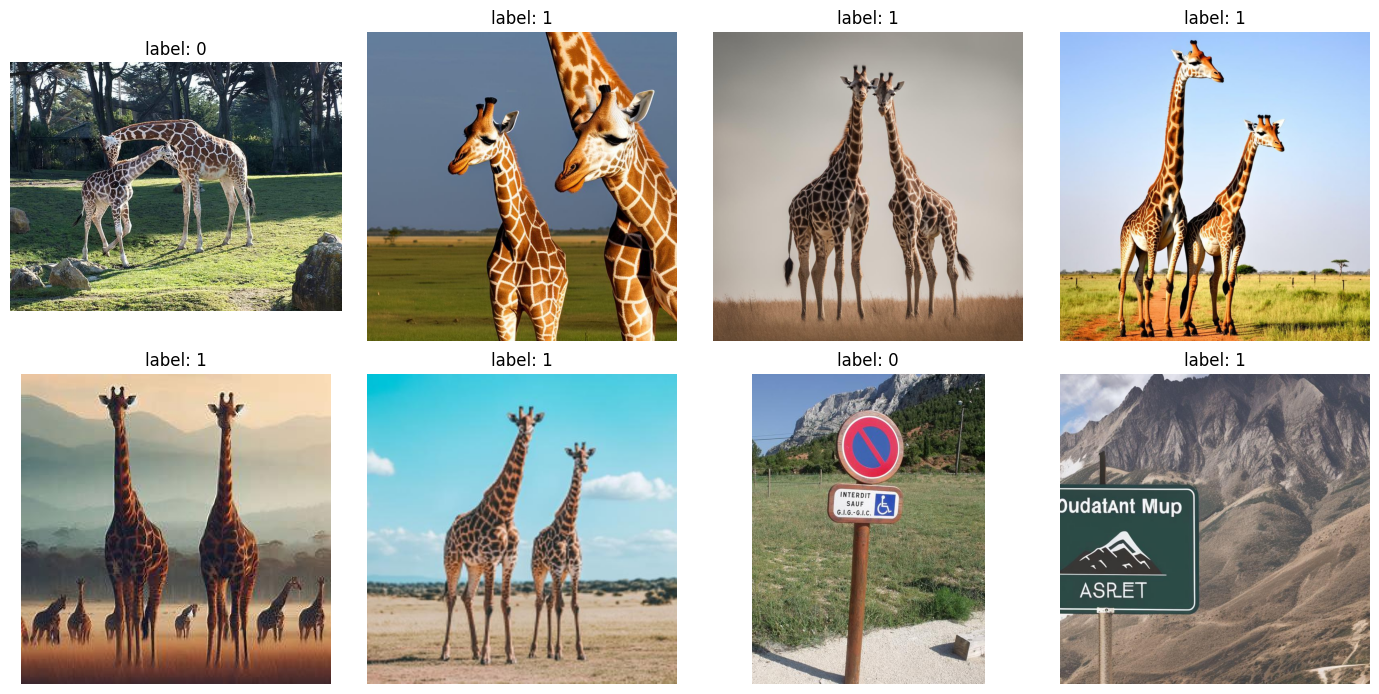

In [8]:
# Visualizar algunas muestras
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, ax in enumerate(axes.flat):
    sample = train_ds_raw[i]
    img = sample[IMAGE_COL]
    ax.imshow(img)
    ax.set_title(f"label: {sample[LABEL_COL]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# ✅ Mapeo confirmado: label 0 = Real, label 1 = Falso (Generada por IA).
# Ver CONFIG["label_mapping"]. Si en algún momento cambias de dataset, vuelve a verificar aquí.


## 3. Dataset y DataModule de PyTorch Lightning

Se define un `Dataset` genérico que aplica las transformaciones según el modelo (cada arquitectura espera una
resolución distinta; la normalización se toma de `timm` en `make_model_and_dm`) y un `LightningDataModule`
reutilizable para ambos experimentos.

> **Proporción de la imagen.** Todas las sintéticas de Defactify son cuadradas y casi ninguna foto real lo es.
> Con `Resize((s, s))` las reales se estiraban y las sintéticas no, y esa deformación podía servir de atajo.
> Ahora se redimensiona el lado corto a `s` y se recorta un cuadrado (aleatorio en train, centrado en val/test).
> Queda una diferencia que no se puede quitar sin cambiar el método: las sintéticas (~1024 px) se reducen más que
> las reales de COCO (~640 px), así que el factor de reducción sigue siendo distinto entre clases.

In [9]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def build_transforms(image_size: int, train: bool, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    # Lado corto a image_size + recorte cuadrado: conserva la proporción (ver nota arriba)
    resize = transforms.Resize(image_size, interpolation=InterpolationMode.BILINEAR, antialias=True)
    if train:
        return transforms.Compose([
            resize,
            transforms.RandomCrop(image_size),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std),
        ])
    else:
        return transforms.Compose([
            resize,
            transforms.CenterCrop(image_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std),
        ])


class HFImageDataset(Dataset):
    """Wrapper de un split de datasets(HF) aplicando transform de torchvision."""
    def __init__(self, hf_dataset, transform, image_col=IMAGE_COL, label_col=LABEL_COL):
        self.ds = hf_dataset
        self.transform = transform
        self.image_col = image_col
        self.label_col = label_col

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        sample = self.ds[idx]
        img = sample[self.image_col]
        if img.mode != "RGB":
            img = img.convert("RGB")
        img = self.transform(img)
        label = int(sample[self.label_col])
        return img, label


class RealVsAIDataModule(L.LightningDataModule):
    def __init__(self, train_raw, val_raw, test_raw, image_size, batch_size, num_workers,
                 mean=IMAGENET_MEAN, std=IMAGENET_STD):
        super().__init__()
        self.train_raw = train_raw
        self.val_raw = val_raw
        self.test_raw = test_raw
        self.image_size = image_size
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.mean = mean
        self.std = std

    def setup(self, stage=None):
        self.train_dataset = HFImageDataset(self.train_raw, build_transforms(self.image_size, train=True, mean=self.mean, std=self.std))
        self.val_dataset = HFImageDataset(self.val_raw, build_transforms(self.image_size, train=False, mean=self.mean, std=self.std))
        self.test_dataset = HFImageDataset(self.test_raw, build_transforms(self.image_size, train=False, mean=self.mean, std=self.std))

    def train_dataloader(self):
        return DataLoader(self.train_dataset, batch_size=self.batch_size, shuffle=True,
                           num_workers=self.num_workers, pin_memory=True, drop_last=True)

    def val_dataloader(self):
        return DataLoader(self.val_dataset, batch_size=self.batch_size, shuffle=False,
                           num_workers=self.num_workers, pin_memory=True)

    def test_dataloader(self):
        return DataLoader(self.test_dataset, batch_size=self.batch_size, shuffle=False,
                           num_workers=self.num_workers, pin_memory=True)

## 4. LightningModule genérico

Una sola clase reutilizable para ambos modelos: recibe el `model_name` de `timm`, arma el backbone
con cabeza binaria, y calcula todas las métricas relevantes en cada fase (train/val/test).

In [10]:
class ImageClassifierModule(L.LightningModule):
    def __init__(self, model_name: str, num_classes: int, lr: float, weight_decay: float,
                 warmup_ratio: float = 0.0, pos_weight: float = None):
        super().__init__()
        self.save_hyperparameters()

        # num_classes=1 -> salida logit único para clasificación binaria (BCEWithLogits)
        self.backbone = timm.create_model(model_name, pretrained=True, num_classes=1)

        # pos_weight = n_negativos / n_positivos compensa el desbalance (None = pérdida sin pesos)
        pw = torch.tensor([pos_weight]) if pos_weight else None
        self.criterion = nn.BCEWithLogitsLoss(pos_weight=pw)

        metrics_args = {}
        self.train_acc = BinaryAccuracy(**metrics_args)
        self.val_acc = BinaryAccuracy(**metrics_args)
        self.test_acc = BinaryAccuracy(**metrics_args)

        self.val_precision = BinaryPrecision()
        self.val_recall = BinaryRecall()
        self.val_f1 = BinaryF1Score()
        self.val_auroc = BinaryAUROC()

        self.test_precision = BinaryPrecision()
        self.test_recall = BinaryRecall()
        self.test_f1 = BinaryF1Score()
        self.test_auroc = BinaryAUROC()
        self.test_confmat = BinaryConfusionMatrix()

    def forward(self, x):
        return self.backbone(x).squeeze(1)  # logits

    def _step(self, batch):
        x, y = batch
        y = y.float()
        logits = self(x)
        loss = self.criterion(logits, y)
        probs = torch.sigmoid(logits)
        return loss, probs, y.int()

    def training_step(self, batch, batch_idx):
        loss, probs, y = self._step(batch)
        self.train_acc(probs, y)
        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.log("train_acc", self.train_acc, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        loss, probs, y = self._step(batch)
        self.val_acc(probs, y)
        self.val_precision(probs, y)
        self.val_recall(probs, y)
        self.val_f1(probs, y)
        self.val_auroc(probs, y)
        self.log("val_loss", loss, prog_bar=True)
        self.log("val_acc", self.val_acc, prog_bar=True)
        self.log("val_precision", self.val_precision)
        self.log("val_recall", self.val_recall)
        self.log("val_f1", self.val_f1, prog_bar=True)
        self.log("val_auroc", self.val_auroc)
        return loss

    def test_step(self, batch, batch_idx):
        loss, probs, y = self._step(batch)
        self.test_acc(probs, y)
        self.test_precision(probs, y)
        self.test_recall(probs, y)
        self.test_f1(probs, y)
        self.test_auroc(probs, y)
        self.test_confmat.update(probs, y)
        self.log("test_loss", loss)
        self.log("test_acc", self.test_acc)
        self.log("test_precision", self.test_precision)
        self.log("test_recall", self.test_recall)
        self.log("test_f1", self.test_f1)
        self.log("test_auroc", self.test_auroc)
        return loss

    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(self.parameters(), lr=self.hparams.lr,
                                       weight_decay=self.hparams.weight_decay)
        if self.hparams.warmup_ratio > 0:
            # Warmup lineal + coseno, actualizado en cada paso de optimización
            total = int(self.trainer.estimated_stepping_batches)
            warmup = max(1, int(total * self.hparams.warmup_ratio))
            warm = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=1e-3, end_factor=1.0, total_iters=warmup)
            cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, total - warmup))
            scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, [warm, cosine], milestones=[warmup])
            return {"optimizer": optimizer, "lr_scheduler": {"scheduler": scheduler, "interval": "step"}}
        # Receta original (EfficientNet-B4): coseno por época, sin warmup
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=self.trainer.max_epochs)
        return {"optimizer": optimizer, "lr_scheduler": scheduler}


## 5. Función de entrenamiento reutilizable

Encapsula el flujo completo (DataModule -> Trainer -> fit -> test) y devuelve métricas,
tiempos y el modelo entrenado, para poder llamarla de forma idéntica con ambas arquitecturas.

Además de las métricas de Lightning (umbral 0.5), se calculan las probabilidades de validación y test. Con las de
validación se elige el umbral; con las de test se reportan las métricas a 0.5 y al umbral elegido.

In [11]:
@torch.no_grad()
def predict_probs(model, loader):
    """Probabilidad de 'IA' para cada imagen del loader (en el mismo orden del dataset)."""
    model.eval().to(DEVICE)
    probs = []
    for x, _ in loader:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            logits = model(x.to(DEVICE, non_blocking=True))
        probs.append(torch.sigmoid(logits.float()).cpu())
    return torch.cat(probs).numpy()


def best_f1_threshold(y, p):
    """Umbral que maximiza el F1 (clase IA) en el conjunto dado. Se usa solo con validación."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.argmax(f1)])


def metrics_at(y, p, threshold):
    y_hat = (p >= threshold).astype(int)
    return {
        "umbral": float(threshold),
        "acc": accuracy_score(y, y_hat),
        "bal_acc": balanced_accuracy_score(y, y_hat),
        "precision": precision_score(y, y_hat, zero_division=0),
        "recall": recall_score(y, y_hat, zero_division=0),
        "f1": f1_score(y, y_hat, zero_division=0),
        "f1_real": f1_score(y, y_hat, pos_label=0, zero_division=0),
        "auroc": roc_auc_score(y, p),
        "confusion_matrix": confusion_matrix(y, y_hat, labels=[0, 1]),
    }


def make_model_and_dm(cfg, train_raw, val_raw, test_raw):
    """Arma LightningModule + DataModule con la receta de cada modelo (lo usan el entrenamiento y la CV)."""
    pos_weight = None
    if cfg.get("use_pos_weight", False):
        y = np.array(train_raw[LABEL_COL])
        pos_weight = float((y == 0).sum() / max(1, (y == 1).sum()))  # negativos / positivos

    model = ImageClassifierModule(
        model_name=cfg["model_name"], num_classes=CONFIG["num_classes"],
        lr=cfg.get("lr", CONFIG["lr"]), weight_decay=CONFIG["weight_decay"],
        warmup_ratio=cfg.get("warmup_ratio", 0.0), pos_weight=pos_weight,
    )
    # Normalización que espera cada modelo (ImageNet para EfficientNet; el ViT de timm puede usar 0.5/0.5)
    data_cfg = timm.data.resolve_data_config({}, model=model.backbone)
    mean, std = list(data_cfg["mean"]), list(data_cfg["std"])
    print(f"lr={model.hparams.lr} | warmup_ratio={model.hparams.warmup_ratio} | pos_weight={pos_weight} | mean={mean} std={std}")

    dm = RealVsAIDataModule(
        train_raw=train_raw, val_raw=val_raw, test_raw=test_raw,
        image_size=cfg["image_size"], batch_size=cfg["batch_size"],
        num_workers=CONFIG["num_workers"], mean=mean, std=std,
    )
    return model, dm, mean, std


def _train_experiment(model_key: str):
    cfg = CONFIG[model_key]
    monitor = cfg.get("monitor", "val_f1")
    print(f"\n{'='*60}\nEntrenando: {cfg['model_name']}\n{'='*60}")
    L.seed_everything(SEED, workers=True)  # misma semilla para cada modelo, sin importar el orden de las celdas

    model, dm, norm_mean, norm_std = make_model_and_dm(cfg, train_ds_raw, val_ds_raw, test_ds_raw)

    n_params = sum(p.numel() for p in model.parameters())
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

    logger = CSVLogger(os.path.join(LOG_DIR, "lightning_logs"), name=model_key)
    callbacks = [
        EarlyStopping(
            monitor=monitor, mode="max",
            patience=cfg.get("patience_early_stop", CONFIG["patience_early_stop"]),
            min_delta=CONFIG["min_delta_early_stop"],
            verbose=True,  # imprime en log cuándo evalúa y por qué decide parar
        ),
        ModelCheckpoint(monitor=monitor, mode="max", filename="best-{epoch}-{step}"),
        LearningRateMonitor(logging_interval="epoch"),
    ]

    trainer = L.Trainer(
        max_epochs=CONFIG["max_epochs"],
        accelerator="auto",
        devices="auto",
        precision=CONFIG["precision"] if DEVICE == "cuda" else "32-true",
        accumulate_grad_batches=cfg["accumulate_grad_batches"],
        gradient_clip_val=cfg.get("grad_clip"),
        logger=logger,
        callbacks=callbacks,
        deterministic=True,
        log_every_n_steps=10,
        # Clave para que una época "larga" no sea un problema:
        # valida (y evalúa EarlyStopping) varias veces DENTRO de cada época,
        # en vez de esperar a que termine por completo.
        val_check_interval=CONFIG["val_check_interval"],
        num_sanity_val_steps=1,  # valida solo 1 batch antes de empezar, para detectar errores rápido sin perder tiempo
    )

    start = time.time()
    trainer.fit(model, datamodule=dm)
    train_time = time.time() - start

    best_val_score = float(trainer.checkpoint_callback.best_model_score)

    # Pesos del mejor checkpoint (elegido con validación)
    ckpt = torch.load(trainer.checkpoint_callback.best_model_path, map_location="cpu", weights_only=False)
    model.load_state_dict(ckpt["state_dict"])

    # Curvas de validación: se copian a OUT_DIR para que sobrevivan a la sesión
    curves_path = os.path.join(OUT_DIR, f"curvas_{model_key}.csv")
    shutil.copy(os.path.join(logger.log_dir, "metrics.csv"), curves_path)

    # Probabilidades por imagen: el umbral se elige en validación y se aplica al test
    dm.setup()
    y_val, y_test = labels_of(val_ds_raw), labels_of(test_ds_raw)
    p_val = predict_probs(model, dm.val_dataloader())
    p_test = predict_probs(model, dm.test_dataloader())
    threshold = best_f1_threshold(y_val, p_val) if CONFIG["tune_threshold_on_val"] else 0.5
    val_metrics = metrics_at(y_val, p_val, threshold)
    test_05 = metrics_at(y_test, p_test, 0.5)
    test_thr = metrics_at(y_test, p_test, threshold)
    print(f"Umbral elegido en validación: {threshold:.4f} | "
          f"test F1 a 0.5 = {test_05['f1']:.4f}, al umbral = {test_thr['f1']:.4f} | test AUROC = {test_05['auroc']:.4f}")

    # Latencia de inferencia en fp32, mismo batch para los dos modelos
    model.eval().float().to(DEVICE)
    lat_loader = DataLoader(dm.test_dataset, batch_size=CONFIG["latency_batch_size"], shuffle=False)
    x, _ = next(iter(lat_loader))
    x = x.to(DEVICE)
    with torch.no_grad():
        for _ in range(5):  # warmup
            _ = model(x)
        torch.cuda.synchronize() if DEVICE == "cuda" else None
        t0 = time.time()
        n_reps = 20
        for _ in range(n_reps):
            _ = model(x)
        torch.cuda.synchronize() if DEVICE == "cuda" else None
        latency_ms = (time.time() - t0) / n_reps * 1000 / x.size(0)  # ms por imagen

    return {
        "model_key": model_key,
        "model_name": cfg["model_name"],
        "norm_mean": norm_mean,
        "norm_std": norm_std,
        "n_params": n_params,
        "n_trainable": n_trainable,
        "train_time_sec": train_time,
        "epochs_trained": trainer.current_epoch + 1,
        "latency_ms_per_image": latency_ms,
        "best_val_score": best_val_score,     # valor de `monitor` en el mejor checkpoint
        "threshold": threshold,
        "val_probs": p_val,
        "test_probs": p_test,
        "val_metrics": val_metrics,
        "test_05": test_05,
        "test_thr": test_thr,
        "curves_path": curves_path,
        # Solo los pesos del backbone (en CPU), para guardar el modelo final sin reentrenar
        "state_dict": {k: v.detach().cpu() for k, v in model.backbone.state_dict().items()},
        "signature": config_signature(model_key),
    }


def run_experiment(model_key: str):
    """Entrena el modelo, o carga el resultado guardado en OUT_DIR si ya se entrenó con la misma configuración."""
    cache = os.path.join(OUT_DIR, f"resultado_{model_key}.pt")
    if os.path.exists(cache):
        result = torch.load(cache, map_location="cpu", weights_only=False)
        if result.get("signature") == config_signature(model_key):
            print(f"{model_key}: se carga el resultado guardado en {cache} (bórralo si quieres reentrenar).")
            return result
        print(f"{model_key}: la configuración cambió desde la última corrida, se reentrena.")
    result = _train_experiment(model_key)
    torch.save(result, cache)
    print(f"{model_key}: resultado guardado en {cache}")
    return result

## 5b. Barridos de learning rate (opcionales, desactivados por defecto)

Se prueban varios `lr` con el resto de la receta fija y se comparan **solo con métricas de validación**; el test no se toca.
Si activas un barrido, el mejor `lr` se copia solo a `CONFIG` y el entrenamiento de las secciones 6 y 7 lo usa.

- Están apagados porque con el dataset completo cada barrido suma varias horas. El `lr` del ViT (1e-5) se eligió con el
  barrido de la versión 3, hecho con el 15 % del train; el de EfficientNet (3e-4) es la receta original.
- Cada corrida usa la misma semilla. Con una sola semilla, diferencias pequeñas entre lr cercanos pueden ser ruido.
- La columna `colapsó` marca las corridas con `val_auroc` < 0.6.

In [12]:
SWEEP_LRS = [1e-5, 3e-5, 1e-4]


def run_lr_sweep(lrs, model_key="vit"):
    base_cfg = CONFIG[model_key]
    monitor = base_cfg.get("monitor", "val_f1")
    rows = []

    for lr in lrs:
        cfg = {**base_cfg, "lr": lr}
        print(f"\n{'='*60}\nBarrido {cfg['model_name']} | lr={lr:g}\n{'='*60}")
        L.seed_everything(SEED, workers=True)

        # test_raw=val_ds_raw: el test no se usa en el barrido
        model, dm, _, _ = make_model_and_dm(cfg, train_ds_raw, val_ds_raw, val_ds_raw)
        logger = CSVLogger(os.path.join(LOG_DIR, "lightning_logs_sweep"), name=f"{model_key}_lr{lr:g}")
        trainer = L.Trainer(
            max_epochs=CONFIG["max_epochs"],
            accelerator="auto",
            devices="auto",
            precision=CONFIG["precision"] if DEVICE == "cuda" else "32-true",
            accumulate_grad_batches=cfg["accumulate_grad_batches"],
            gradient_clip_val=cfg.get("grad_clip"),
            logger=logger,
            callbacks=[
                EarlyStopping(monitor=monitor, mode="max",
                              patience=cfg.get("patience_early_stop", CONFIG["patience_early_stop"]),
                              min_delta=CONFIG["min_delta_early_stop"]),
                ModelCheckpoint(monitor=monitor, mode="max", filename="best"),
            ],
            deterministic=True,
            log_every_n_steps=10,
            val_check_interval=CONFIG["val_check_interval"],
            num_sanity_val_steps=1,
            enable_model_summary=False,
        )

        start = time.time()
        trainer.fit(model, datamodule=dm)
        elapsed = time.time() - start
        val = trainer.validate(model, datamodule=dm, ckpt_path="best", verbose=False)[0]

        rows.append({
            "lr": lr,
            "val_auroc": val["val_auroc"],
            "val_f1": val["val_f1"],
            "val_precision": val["val_precision"],
            "val_recall": val["val_recall"],
            "épocas": trainer.current_epoch + 1,
            "tiempo (s)": round(elapsed, 1),
            "colapsó": val["val_auroc"] < 0.6,
        })

    return pd.DataFrame(rows).sort_values("val_auroc", ascending=False).reset_index(drop=True)

In [13]:
RUN_VIT_SWEEP = False

if RUN_VIT_SWEEP:
    sweep_df = run_lr_sweep(SWEEP_LRS, model_key="vit")
    sweep_df.to_csv(os.path.join(OUT_DIR, "barrido_lr_vit.csv"), index=False)
    display(sweep_df.assign(lr=sweep_df["lr"].map("{:g}".format)).round(4))
    CONFIG["vit"]["lr"] = float(sweep_df.loc[0, "lr"])
    print(f'Mejor lr del ViT por val_auroc: {CONFIG["vit"]["lr"]:g} (ya quedó en CONFIG["vit"]["lr"])')

### Barrido de EfficientNet-B4

In [14]:
RUN_EFF_SWEEP = False

if RUN_EFF_SWEEP:
    eff_sweep_df = run_lr_sweep([1e-4, 3e-4, 1e-3], model_key="efficientnet")
    eff_sweep_df.to_csv(os.path.join(OUT_DIR, "barrido_lr_efficientnet.csv"), index=False)
    display(eff_sweep_df.assign(lr=eff_sweep_df["lr"].map("{:g}".format)).round(4))
    CONFIG["efficientnet"]["lr"] = float(eff_sweep_df.loc[0, "lr"])
    print(f'Mejor lr de EfficientNet por val_f1: {CONFIG["efficientnet"]["lr"]:g} (ya quedó en CONFIG["efficientnet"]["lr"])')

## 6. Entrenar EfficientNet-B4

In [15]:
efficientnet_results = run_experiment("efficientnet")

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42



Entrenando: efficientnet_b4


model.safetensors: reconstructing file:   0%|          |  0.00B / 77.9MB            

model.safetensors: downloading bytes:           |  0.00B            

INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: You are using a CUDA device ('NVIDIA RTX PRO 6000 Blackwell Server Edition') that has Tens

lr=0.0003 | warmup_ratio=0.0 | pos_weight=None | mean=[0.485, 0.456, 0.406] std=[0.229, 0.224, 0.225]


... (3 outputs left out)

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO: Metric val_f1 improved. New best score: 0.988
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_f1 improved. New best score: 0.988
INFO: Metric val_f1 improved by 0.005 >= min_delta = 0.001. New best score: 0.993
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_f1 improved by 0.005 >= min_delta = 0.001. New best score: 0.993
INFO: Metric val_f1 improved by 0.004 >= min_delta = 0.001. New best score: 0.997
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_f1 improved by 0.004 >= min_delta = 0.001. New best score: 0.997
INFO: Monitored metric val_f1 did not improve in the last 3 records. Best score: 0.997. Signaling Trainer to stop.
INFO:lightning.pytorch.callbacks.early_stopping:Monitored metric val_f1 did not improve in the last 3 records. Best score: 0.997. Signaling Trainer to stop.


Umbral elegido en validación: 0.7463 | test F1 a 0.5 = 0.9813, al umbral = 0.9720 | test AUROC = 0.9984
efficientnet: resultado guardado en /content/drive/MyDrive/tesis_deteccion_ia_v4/resultado_efficientnet.pt


## 7. Entrenar ViT-B/16

In [16]:
vit_results = run_experiment("vit")

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42



Entrenando: vit_base_patch16_224


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_R

lr=1e-05 | warmup_ratio=0.1 | pos_weight=0.2 | mean=[0.5, 0.5, 0.5] std=[0.5, 0.5, 0.5]


... (2 outputs left out)

Trainable params: 85.8 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 85.8 M                                                                                               
Total estimated model params size (MB): 343.198                                                                    
Modules in train mode: 289                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO: Metric val_auroc improved. New best score: 0.951
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_auroc improved. New best score: 0.951
INFO: Metric val_auroc improved by 0.046 >= min_delta = 0.001. New best score: 0.997
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_auroc improved by 0.046 >= min_delta = 0.001. New best score: 0.997
INFO: Metric val_auroc improved by 0.001 >= min_delta = 0.001. New best score: 0.999
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_auroc improved by 0.001 >= min_delta = 0.001. New best score: 0.999
INFO: Metric val_auroc improved by 0.001 >= min_delta = 0.001. New best score: 1.000
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_auroc improved by 0.001 >= min_delta = 0.001. New best score: 1.000
INFO: Monitored metric val_auroc did not improve in the last 8 records. Best score: 1.000. Signaling Trainer to stop.
INFO:lightning.pytorch.callbacks.early_stopping:Monitored metric val_auroc did not improve in 

Umbral elegido en validación: 0.0024 | test F1 a 0.5 = 0.9601, al umbral = 0.9846 | test AUROC = 0.9980
vit: resultado guardado en /content/drive/MyDrive/tesis_deteccion_ia_v4/resultado_vit.pt


## 8. Comparación de resultados (test)

**Cómo leer la tabla**:
- Con el desbalance del dataset (aprox. 83 % IA), un modelo que responde "IA" a todo obtiene accuracy ≈ 0.83, recall 1.0 y F1 ≈ 0.91.
  Por eso se reportan también AUROC, accuracy balanceada y el F1 de la clase real, que no se dejan engañar por ese clasificador trivial.
- **Umbral 0.5 vs. umbral de validación.** El ViT entrena con `pos_weight` y EfficientNet no, así que sus probabilidades
  no están en la misma escala; con 0.5 la comparación de precisión/recall/F1 favorece a uno u otro por la escala, no por lo que aprendió.
  Las columnas "(umbral val)" usan el umbral elegido en validación y son la comparación más justa. AUROC no depende del umbral.
- El **tiempo de entrenamiento** depende de cuándo el `EarlyStopping` detuvo a cada modelo y de la GPU de la sesión.
- La **latencia** se mide en fp32 sobre el mismo número de imágenes por batch para los dos; es una referencia, no un benchmark.

In [17]:
comparison_df = pd.DataFrame([
    {
        "Modelo": r["model_name"],
        "Parámetros (M)": round(r["n_params"] / 1e6, 2),
        "AUROC": round(r["test_05"]["auroc"], 4),
        "Acc (0.5)": round(r["test_05"]["acc"], 4),
        "Bal. acc (0.5)": round(r["test_05"]["bal_acc"], 4),
        "Precision (0.5)": round(r["test_05"]["precision"], 4),
        "Recall (0.5)": round(r["test_05"]["recall"], 4),
        "F1 (0.5)": round(r["test_05"]["f1"], 4),
        "Umbral val": round(r["threshold"], 4),
        "Bal. acc (umbral val)": round(r["test_thr"]["bal_acc"], 4),
        "Precision (umbral val)": round(r["test_thr"]["precision"], 4),
        "Recall (umbral val)": round(r["test_thr"]["recall"], 4),
        "F1 (umbral val)": round(r["test_thr"]["f1"], 4),
        "F1 real (umbral val)": round(r["test_thr"]["f1_real"], 4),
        "Épocas": r["epochs_trained"],
        "Tiempo entrenamiento (s)": round(r["train_time_sec"], 1),
        "Latencia (ms/img)": round(r["latency_ms_per_image"], 2),
    }
    for r in [efficientnet_results, vit_results]
])

comparison_df.T

,0,1
Modelo,efficientnet_b4,vit_base_patch16_224
Parámetros (M),17.55,85.8
AUROC,0.9984,0.998
Acc (0.5),0.9694,0.936
Bal. acc (0.5),0.9777,0.9609
Precision (0.5),0.998,0.9996
Recall (0.5),0.9652,0.9235
F1 (0.5),0.9813,0.9601
Umbral val,0.7463,0.0024
Bal. acc (umbral val),0.9704,0.9788


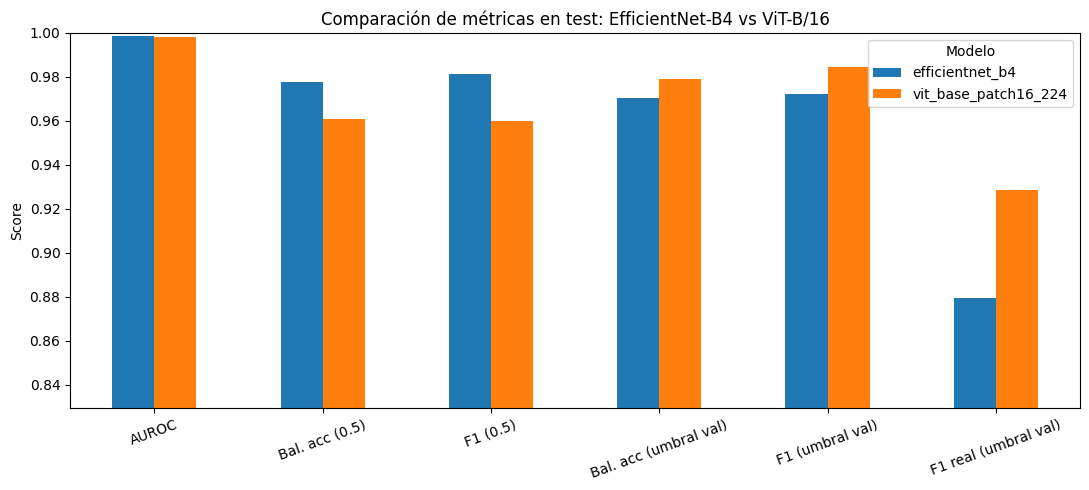

In [18]:
# Gráfico de barras comparando métricas de clasificación
metrics_to_plot = ["AUROC", "Bal. acc (0.5)", "F1 (0.5)", "Bal. acc (umbral val)", "F1 (umbral val)", "F1 real (umbral val)"]
plot_df = comparison_df.set_index("Modelo")[metrics_to_plot]

ax = plot_df.T.plot(kind="bar", figsize=(11, 5), rot=20)
ax.set_ylabel("Score")
ax.set_ylim(max(0, plot_df.values.min() - 0.05), 1)
ax.set_title("Comparación de métricas en test: EfficientNet-B4 vs ViT-B/16")
ax.legend(title="Modelo")
plt.tight_layout()
plt.show()

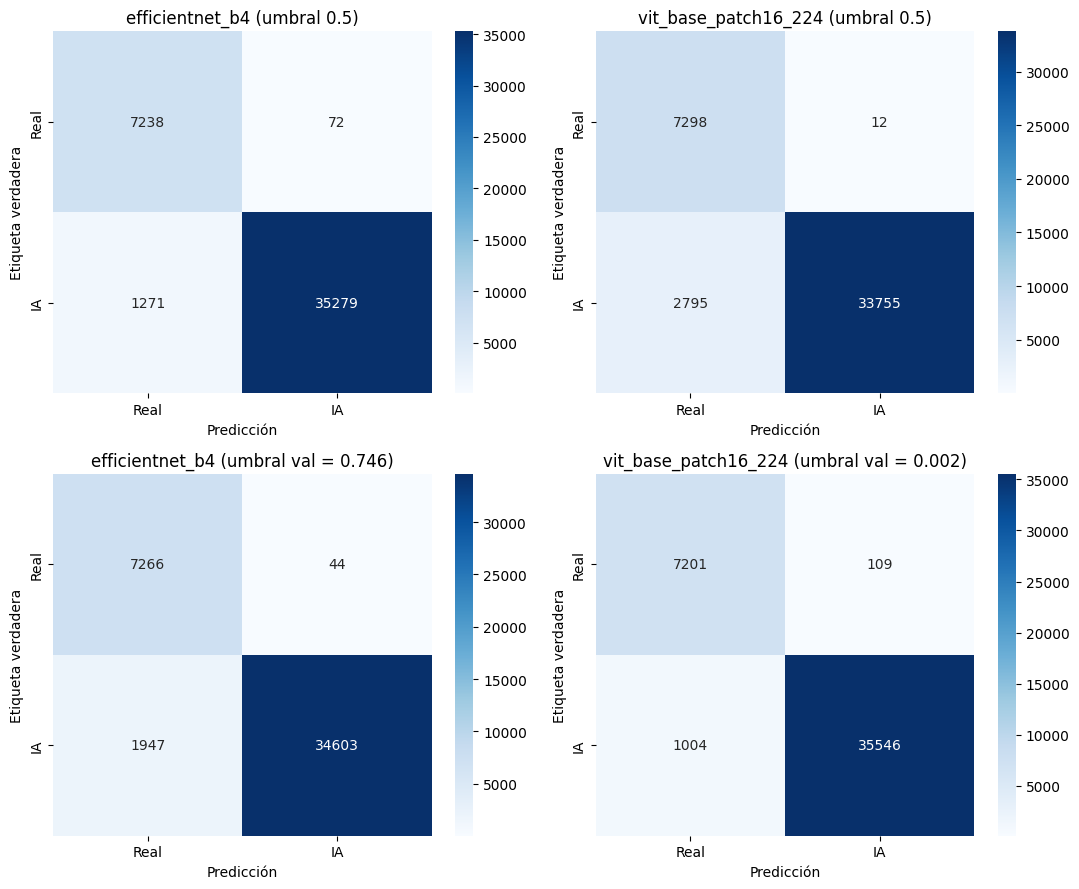

In [19]:
# Matrices de confusión lado a lado: umbral 0.5 (arriba) y umbral elegido en validación (abajo)
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for col, r in enumerate([efficientnet_results, vit_results]):
    for row, (key, label) in enumerate([("test_05", "umbral 0.5"), ("test_thr", f"umbral val = {r['threshold']:.3f}")]):
        ax = axes[row, col]
        sns.heatmap(r[key]["confusion_matrix"], annot=True, fmt="d", cmap="Blues", ax=ax,
                    xticklabels=["Real", "IA"], yticklabels=["Real", "IA"])
        ax.set_title(f"{r['model_name']} ({label})")
        ax.set_xlabel("Predicción")
        ax.set_ylabel("Etiqueta verdadera")
plt.tight_layout()
plt.show()

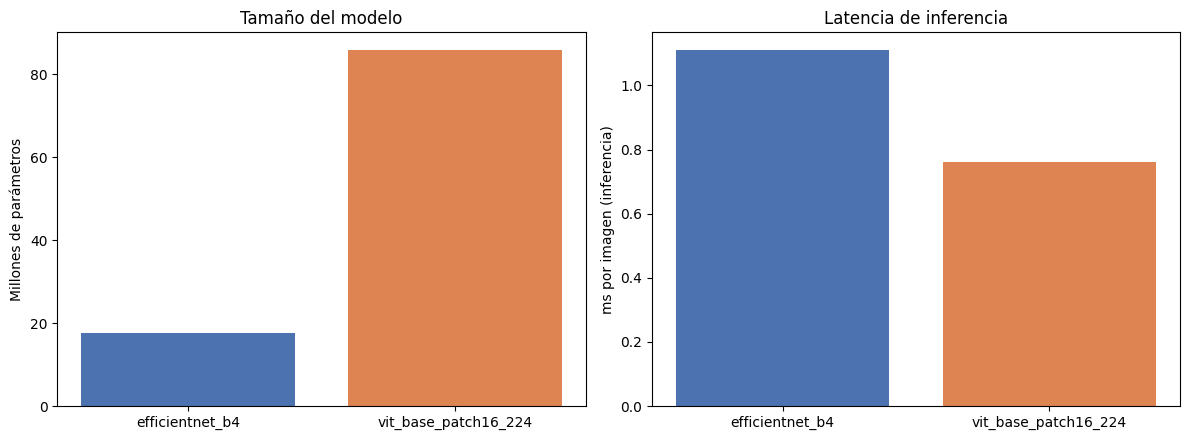

In [20]:
# Eficiencia: número de parámetros y latencia de inferencia
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(comparison_df["Modelo"], comparison_df["Parámetros (M)"], color=["#4C72B0", "#DD8452"])
axes[0].set_ylabel("Millones de parámetros")
axes[0].set_title("Tamaño del modelo")

axes[1].bar(comparison_df["Modelo"], comparison_df["Latencia (ms/img)"], color=["#4C72B0", "#DD8452"])
axes[1].set_ylabel("ms por imagen (inferencia)")
axes[1].set_title("Latencia de inferencia")

plt.tight_layout()
plt.show()


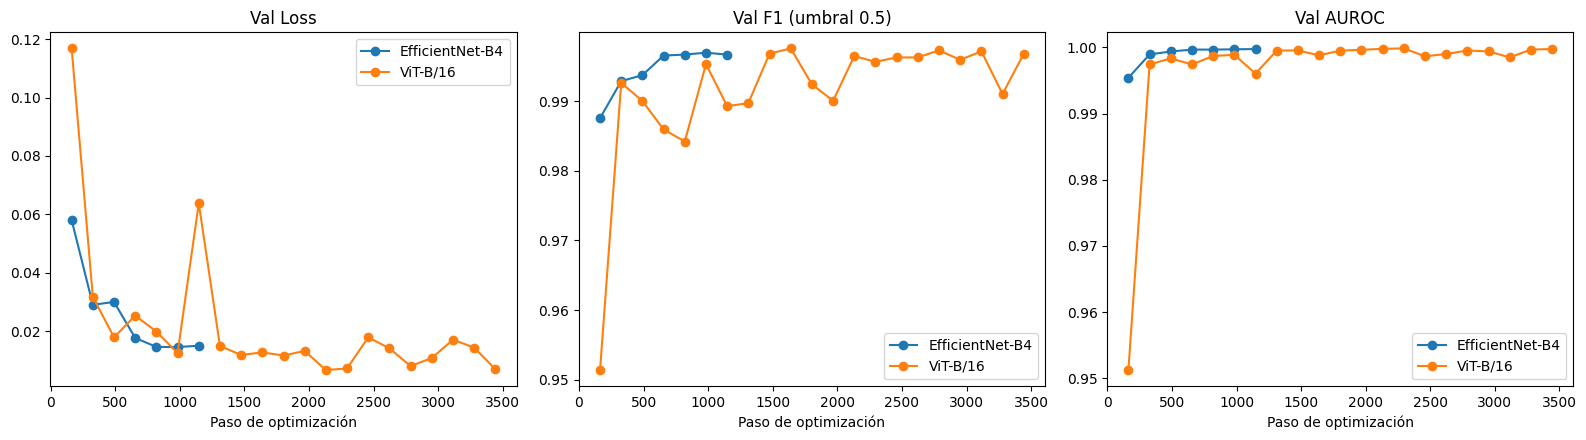

In [21]:
# Curvas de validación (loss / F1 / AUROC, 4 validaciones por época) leídas desde los logs de CSVLogger
eff_metrics = pd.read_csv(efficientnet_results["curves_path"])
vit_metrics = pd.read_csv(vit_results["curves_path"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for df, name in [(eff_metrics, "EfficientNet-B4"), (vit_metrics, "ViT-B/16")]:
    for ax, col in zip(axes, ["val_loss", "val_f1", "val_auroc"]):
        if col in df:
            d = df.dropna(subset=[col])
            ax.plot(d["step"], d[col], label=name, marker="o")

for ax, title in zip(axes, ["Val Loss", "Val F1 (umbral 0.5)", "Val AUROC"]):
    ax.set_title(title); ax.set_xlabel("Paso de optimización"); ax.legend()
plt.tight_layout()
plt.show()

### 8b. ¿La diferencia en test es real? Bootstrap por escena y McNemar

- **Bootstrap por escena**: se remuestrean escenas completas (no imágenes), porque las imágenes de una misma escena
  no son independientes. Da intervalos del 95 % para cada modelo y para la diferencia entre ellos; si el intervalo de
  la diferencia incluye el 0, el test no permite decir que un modelo sea mejor.
- **McNemar** compara los aciertos de los dos modelos imagen por imagen. Supone imágenes independientes, así que es
  algo optimista con este dataset; el bootstrap por escena es la referencia.
- Las predicciones por imagen se guardan en `predicciones_val.csv` y `predicciones_test.csv` dentro de `OUT_DIR`.

In [22]:
from statsmodels.stats.contingency_tables import mcnemar

y_test = labels_of(test_ds_raw)
g_test = scene_keys(test_ds_raw)
p_eff, p_vit = efficientnet_results["test_probs"], vit_results["test_probs"]
thr_eff, thr_vit = efficientnet_results["threshold"], vit_results["threshold"]

# --- Guardar predicciones por imagen ---
pd.DataFrame({
    "escena": g_test, "label": y_test,
    "p_efficientnet": p_eff, "p_vit": p_vit,
}).to_csv(os.path.join(OUT_DIR, "predicciones_test.csv"), index=False)
pd.DataFrame({
    "escena": scene_keys(val_ds_raw), "label": labels_of(val_ds_raw),
    "p_efficientnet": efficientnet_results["val_probs"], "p_vit": vit_results["val_probs"],
}).to_csv(os.path.join(OUT_DIR, "predicciones_val.csv"), index=False)
print("Predicciones guardadas en", OUT_DIR)


# --- Bootstrap por escena ---
def boot_metrics(y, p, thr):
    y_hat = (p >= thr).astype(int)
    return {"AUROC": roc_auc_score(y, p), "F1": f1_score(y, y_hat, zero_division=0),
            "Bal. acc": balanced_accuracy_score(y, y_hat), "F1 real": f1_score(y, y_hat, pos_label=0, zero_division=0)}


def cluster_bootstrap(y, p_a, p_b, thr_a, thr_b, groups, n_boot, seed=SEED):
    uniq, inv = np.unique(groups, return_inverse=True)
    order = np.argsort(inv, kind="stable")
    members = np.split(order, np.cumsum(np.bincount(inv))[:-1])
    rng = np.random.default_rng(seed)
    rows = []
    for _ in range(n_boot):
        idx = np.concatenate([members[g] for g in rng.integers(0, len(uniq), len(uniq))])
        if y[idx].min() == y[idx].max():
            continue
        ma, mb = boot_metrics(y[idx], p_a[idx], thr_a), boot_metrics(y[idx], p_b[idx], thr_b)
        rows.append({**{f"{k}|A": v for k, v in ma.items()}, **{f"{k}|B": v for k, v in mb.items()}})
    return pd.DataFrame(rows)


def ci(s):
    return f"[{s.quantile(0.025):.4f}, {s.quantile(0.975):.4f}]"


for label, (ta, tb) in {"umbral 0.5": (0.5, 0.5), "umbral de validación": (thr_eff, thr_vit)}.items():
    boot = cluster_bootstrap(y_test, p_eff, p_vit, ta, tb, g_test, CONFIG["n_bootstrap"])
    point_a, point_b = boot_metrics(y_test, p_eff, ta), boot_metrics(y_test, p_vit, tb)
    table = []
    for m in point_a:
        diff = boot[f"{m}|B"] - boot[f"{m}|A"]
        table.append({"Métrica": m,
                      "EfficientNet-B4": f"{point_a[m]:.4f} {ci(boot[f'{m}|A'])}",
                      "ViT-B/16": f"{point_b[m]:.4f} {ci(boot[f'{m}|B'])}",
                      "ViT − EfficientNet": f"{point_b[m] - point_a[m]:+.4f} {ci(diff)}"})
    print(f"\nTest, {label} — IC 95 % por bootstrap de escenas ({len(boot)} remuestreos)")
    display(pd.DataFrame(table))

    # McNemar sobre los aciertos imagen por imagen
    ok_e = (p_eff >= ta).astype(int) == y_test
    ok_v = (p_vit >= tb).astype(int) == y_test
    tabla = [[(ok_e & ok_v).sum(), (ok_e & ~ok_v).sum()],
             [(~ok_e & ok_v).sum(), (~ok_e & ~ok_v).sum()]]
    res = mcnemar(tabla, exact=False, correction=True)
    print(f"McNemar ({label}): solo EfficientNet acierta = {tabla[0][1]}, solo ViT acierta = {tabla[1][0]}, "
          f"chi2 = {res.statistic:.2f}, p = {res.pvalue:.4g}")

Predicciones guardadas en /content/drive/MyDrive/tesis_deteccion_ia_v4

Test, umbral 0.5 — IC 95 % por bootstrap de escenas (1000 remuestreos)


,Métrica,EfficientNet-B4,ViT-B/16,ViT − EfficientNet
0,AUROC,"0.9984 [0.9979, 0.9988]","0.9980 [0.9975, 0.9983]","-0.0004 [-0.0009, 0.0000]"
1,F1,"0.9813 [0.9800, 0.9826]","0.9601 [0.9581, 0.9621]","-0.0212 [-0.0232, -0.0194]"
2,Bal. acc,"0.9777 [0.9753, 0.9800]","0.9609 [0.9589, 0.9629]","-0.0167 [-0.0192, -0.0140]"
3,F1 real,"0.9151 [0.9096, 0.9205]","0.8387 [0.8322, 0.8453]","-0.0764 [-0.0833, -0.0693]"


McNemar (umbral 0.5): solo EfficientNet acierta = 2238, solo ViT acierta = 774, chi2 = 710.61, p = 1.471e-156

Test, umbral de validación — IC 95 % por bootstrap de escenas (1000 remuestreos)


,Métrica,EfficientNet-B4,ViT-B/16,ViT − EfficientNet
0,AUROC,"0.9984 [0.9979, 0.9988]","0.9980 [0.9975, 0.9983]","-0.0004 [-0.0009, 0.0000]"
1,F1,"0.9720 [0.9703, 0.9737]","0.9846 [0.9833, 0.9857]","+0.0126 [0.0109, 0.0142]"
2,Bal. acc,"0.9704 [0.9682, 0.9724]","0.9788 [0.9761, 0.9810]","+0.0085 [0.0058, 0.0109]"
3,F1 real,"0.8795 [0.8733, 0.8857]","0.9283 [0.9228, 0.9333]","+0.0488 [0.0423, 0.0550]"


McNemar (umbral de validación): solo EfficientNet acierta = 697, solo ViT acierta = 1575, chi2 = 338.53, p = 1.337e-75


## 9. Validación cruzada (k-fold estratificado por escena)

El entrenamiento anterior (secciones 6-8) usa **un solo split** train/val/test; el resultado puede variar según qué
imágenes cayeron en cada partición. Esta sección corre **k-fold estratificado y agrupado por escena**
(`StratifiedGroupKFold`) sobre train+val para obtener media ± desviación estándar por modelo.

**Por qué agrupado.** Si la foto real de una escena queda en entrenamiento y sus versiones sintéticas en evaluación
(o al revés), el modelo puede apoyarse en el contenido de la escena. En la versión 3 los folds se armaban con imágenes
sueltas y eso inflaba la CV; aquí cada escena cae completa en un solo fold.

**Validación interna.** En cada fold, el `EarlyStopping`, el checkpoint y el umbral se deciden con una validación
interna separada (también por escena) del entrenamiento del fold. Las métricas se miden en el fold de evaluación, que
el modelo no vio en ningún momento. En la versión 3 se paraba y se reportaba sobre el mismo fold, lo que da una
estimación optimista.

**⚠️ Costo de cómputo**: se entrena cada modelo `n_splits` veces (5 por defecto), con `CONFIG["cross_validation"]["max_epochs"]`. Es la parte más larga del notebook. Cada fold terminado queda en `OUT_DIR` y no se repite si la sesión se cae.

El conjunto de **test se mantiene completamente fuera de la cross-validation**.

In [23]:
from sklearn.model_selection import StratifiedGroupKFold
from datasets import concatenate_datasets
from scipy import stats
from scipy.stats import ttest_rel


def get_stratified_group_splits(labels, groups, n_splits, seed):
    """Folds estratificados por clase en los que cada escena queda completa en un solo fold."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return list(sgkf.split(np.zeros(len(labels)), labels, groups))

In [24]:
def run_cross_validation(model_key: str):
    cfg = CONFIG[model_key]
    cv_cfg = CONFIG["cross_validation"]
    monitor = cfg.get("monitor", "val_f1")
    n_splits = cv_cfg["n_splits"]
    inner_k = max(2, round(1 / CONFIG["val_fraction"]))  # validación interna ≈ val_fraction del train del fold

    print(f"\n{'='*60}\nCross-validation ({n_splits}-fold, por escena): {cfg['model_name']}\n{'='*60}")

    # Pool de CV = train + val (el test se mantiene aparte, sin tocar)
    cv_pool = concatenate_datasets([train_ds_raw, val_ds_raw])
    y_pool, g_pool = labels_of(cv_pool), scene_keys(cv_pool)
    splits = get_stratified_group_splits(y_pool, g_pool, n_splits, SEED)  # mismos folds para los dos modelos

    fold_rows = []

    for fold_idx, (train_idx, eval_idx) in enumerate(splits):
        assert not set(g_pool[train_idx]) & set(g_pool[eval_idx]), "Escena repartida entre train y evaluación"

        # Fold ya terminado en una sesión anterior con la misma configuración -> se carga
        fold_cache = os.path.join(OUT_DIR, f"cv_{model_key}_fold{fold_idx + 1}.json")
        if os.path.exists(fold_cache):
            saved = json.load(open(fold_cache, encoding="utf-8"))
            if saved.get("signature") == config_signature(model_key):
                print(f"{cfg['model_name']} | Fold {fold_idx + 1}/{n_splits}: se carga de {fold_cache}")
                fold_rows.append(saved["row"])
                continue

        # Validación interna (por escena) para EarlyStopping, checkpoint y umbral
        inner_fit, inner_es = get_stratified_group_splits(
            y_pool[train_idx], g_pool[train_idx], inner_k, SEED + fold_idx)[0]
        fit_idx, es_idx = train_idx[inner_fit], train_idx[inner_es]

        print(f"\n--- {cfg['model_name']} | Fold {fold_idx + 1}/{n_splits} "
              f"(train={len(fit_idx)}, val interna={len(es_idx)}, evaluación={len(eval_idx)}) ---")

        fold_fit_raw = cv_pool.select(fit_idx.tolist())
        fold_es_raw = cv_pool.select(es_idx.tolist())
        fold_eval_raw = cv_pool.select(eval_idx.tolist())

        L.seed_everything(SEED + fold_idx, workers=True)  # misma semilla por fold para los dos modelos
        model, dm, _, _ = make_model_and_dm(cfg, fold_fit_raw, fold_es_raw, fold_eval_raw)

        logger = CSVLogger(os.path.join(LOG_DIR, "lightning_logs_cv"), name=f"{model_key}_fold{fold_idx}")
        callbacks = [
            EarlyStopping(
                monitor=monitor, mode="max",
                patience=cfg.get("cv_patience_early_stop", cv_cfg["patience_early_stop"]),
                min_delta=CONFIG["min_delta_early_stop"],
            ),
            ModelCheckpoint(monitor=monitor, mode="max", filename="best"),
        ]

        trainer = L.Trainer(
            max_epochs=cv_cfg["max_epochs"],
            accelerator="auto",
            devices="auto",
            precision=CONFIG["precision"] if DEVICE == "cuda" else "32-true",
            accumulate_grad_batches=cfg["accumulate_grad_batches"],
            gradient_clip_val=cfg.get("grad_clip"),
            logger=logger,
            callbacks=callbacks,
            deterministic=True,
            log_every_n_steps=10,
            val_check_interval=CONFIG["val_check_interval"],
            num_sanity_val_steps=1,
            enable_model_summary=(fold_idx == 0),  # solo imprime el resumen del modelo una vez
        )

        trainer.fit(model, datamodule=dm)

        # Pesos del mejor checkpoint (elegido con la validación interna)
        ckpt = torch.load(trainer.checkpoint_callback.best_model_path, map_location="cpu", weights_only=False)
        model.load_state_dict(ckpt["state_dict"])
        dm.setup()

        p_es = predict_probs(model, dm.val_dataloader())
        p_eval = predict_probs(model, dm.test_dataloader())
        y_eval = labels_of(fold_eval_raw)
        thr = best_f1_threshold(labels_of(fold_es_raw), p_es) if CONFIG["tune_threshold_on_val"] else 0.5
        m05, mthr = metrics_at(y_eval, p_eval, 0.5), metrics_at(y_eval, p_eval, thr)

        # Las columnas se llaman val_* por compatibilidad con la versión 3, pero se miden en el fold de evaluación
        row = {
            "fold": fold_idx + 1,
            "n_train": len(train_idx),
            "n_eval": len(eval_idx),
            "val_acc": m05["acc"],
            "val_bal_acc": m05["bal_acc"],
            "val_precision": m05["precision"],
            "val_recall": m05["recall"],
            "val_f1": m05["f1"],
            "val_auroc": m05["auroc"],
            "umbral": float(thr),
            "val_bal_acc_umbral": mthr["bal_acc"],
            "val_f1_umbral": mthr["f1"],
            "val_f1_real_umbral": mthr["f1_real"],
        }
        row = {k: (float(v) if isinstance(v, (np.floating, np.integer)) else v) for k, v in row.items()}
        fold_rows.append(row)
        json.dump({"signature": config_signature(model_key), "row": row}, open(fold_cache, "w", encoding="utf-8"))
        shutil.rmtree(logger.log_dir, ignore_errors=True)  # libera disco: el checkpoint del fold ya no se necesita

    fold_df = pd.DataFrame(fold_rows)
    summary = fold_df.drop(columns=["fold", "n_train", "n_eval"]).agg(["mean", "std"])

    print(f"\nResumen CV — {cfg['model_name']}:")
    print(summary.round(4))

    return {
        "model_key": model_key,
        "model_name": cfg["model_name"],
        "fold_metrics": fold_df,
        "summary": summary,
    }

### Ejecutar cross-validation para ambos modelos

In [25]:
efficientnet_cv = run_cross_validation("efficientnet")


Cross-validation (5-fold, por escena): efficientnet_b4


INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42



--- efficientnet_b4 | Fold 1/5 (train=36606, val interna=4050, evaluación=10158) ---


INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_R

lr=0.0003 | warmup_ratio=0.0 | pos_weight=None | mean=[0.485, 0.456, 0.406] std=[0.229, 0.224, 0.225]


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


... (26 outputs left out)

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

lr=0.0003 | warmup_ratio=0.0 | pos_weight=None | mean=[0.485, 0.456, 0.406] std=[0.229, 0.224, 0.225]



Resumen CV — efficientnet_b4:
      val_acc  val_bal_acc  val_precision  val_recall  val_f1  val_auroc  \
mean   0.9956       0.9919         0.9972      0.9975  0.9974     0.9997   
std    0.0008       0.0009         0.0003      0.0009  0.0005     0.0001   

      umbral  val_bal_acc_umbral  val_f1_umbral  val_f1_real_umbral  
mean  0.5548              0.9916         0.9973              0.9864  
std   0.2071              0.0028         0.0005              0.0026  


In [26]:
vit_cv = run_cross_validation("vit")


Cross-validation (5-fold, por escena): vit_base_patch16_224


INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42



--- vit_base_patch16_224 | Fold 1/5 (train=36606, val interna=4050, evaluación=10158) ---


INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_R

lr=1e-05 | warmup_ratio=0.1 | pos_weight=0.2 | mean=[0.5, 0.5, 0.5] std=[0.5, 0.5, 0.5]


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


... (24 outputs left out)

lr=1e-05 | warmup_ratio=0.1 | pos_weight=0.2 | mean=[0.5, 0.5, 0.5] std=[0.5, 0.5, 0.5]


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()


Resumen CV — vit_base_patch16_224:
      val_acc  val_bal_acc  val_precision  val_recall  val_f1  val_auroc  \
mean   0.9930       0.9867         0.9955      0.9962  0.9958     0.9995   
std    0.0015       0.0060         0.0026      0.0015  0.0009     0.0001   

      umbral  val_bal_acc_umbral  val_f1_umbral  val_f1_real_umbral  
mean  0.4486              0.9870         0.9960              0.9800  
std   0.2194              0.0036         0.0005              0.0027  


### Comparación de resultados de cross-validation

In [27]:
def cv_summary_row(cv_result):
    s = cv_result["summary"]
    def fmt(metric):
        return f"{s.loc['mean', metric]:.4f} ± {s.loc['std', metric]:.4f}"
    return {
        "Modelo": cv_result["model_name"],
        "AUROC": fmt("val_auroc"),
        "Accuracy (0.5)": fmt("val_acc"),
        "Bal. acc (0.5)": fmt("val_bal_acc"),
        "Precision (0.5)": fmt("val_precision"),
        "Recall (0.5)": fmt("val_recall"),
        "F1 (0.5)": fmt("val_f1"),
        "Bal. acc (umbral val)": fmt("val_bal_acc_umbral"),
        "F1 (umbral val)": fmt("val_f1_umbral"),
        "F1 real (umbral val)": fmt("val_f1_real_umbral"),
    }

cv_comparison_df = pd.DataFrame([cv_summary_row(efficientnet_cv), cv_summary_row(vit_cv)])
cv_comparison_df.T

,0,1
Modelo,efficientnet_b4,vit_base_patch16_224
AUROC,0.9997 ± 0.0001,0.9995 ± 0.0001
Accuracy (0.5),0.9956 ± 0.0008,0.9930 ± 0.0015
Bal. acc (0.5),0.9919 ± 0.0009,0.9867 ± 0.0060
Precision (0.5),0.9972 ± 0.0003,0.9955 ± 0.0026
Recall (0.5),0.9975 ± 0.0009,0.9962 ± 0.0015
F1 (0.5),0.9974 ± 0.0005,0.9958 ± 0.0009
Bal. acc (umbral val),0.9916 ± 0.0028,0.9870 ± 0.0036
F1 (umbral val),0.9973 ± 0.0005,0.9960 ± 0.0005
F1 real (umbral val),0.9864 ± 0.0026,0.9800 ± 0.0027


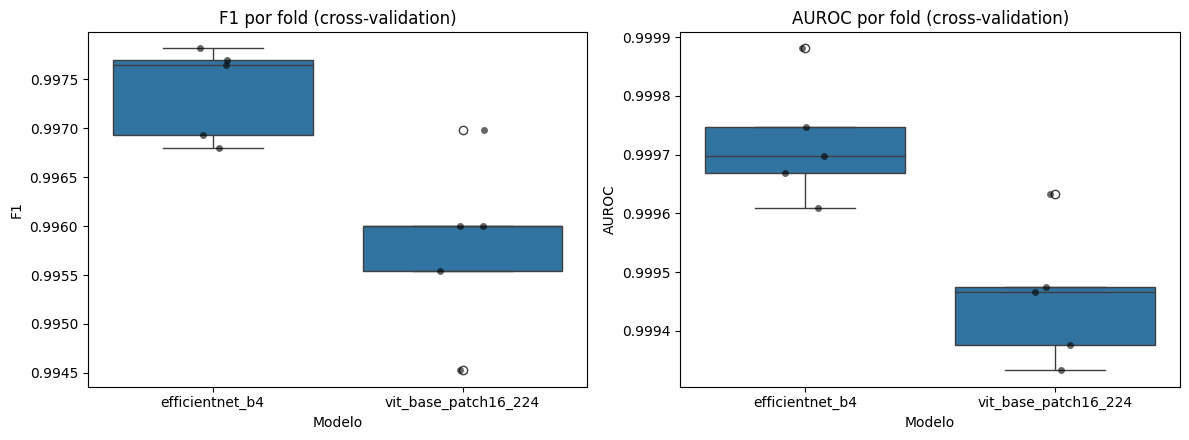

In [28]:
# Distribución de F1 por fold -- ¿la diferencia entre modelos es consistente o es ruido?
combined_folds = pd.concat([
    efficientnet_cv["fold_metrics"].assign(Modelo=efficientnet_cv["model_name"]),
    vit_cv["fold_metrics"].assign(Modelo=vit_cv["model_name"]),
])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=combined_folds, x="Modelo", y="val_f1", ax=axes[0])
sns.stripplot(data=combined_folds, x="Modelo", y="val_f1", color="black", alpha=0.6, ax=axes[0])
axes[0].set_title("F1 por fold (cross-validation)")
axes[0].set_ylabel("F1")

sns.boxplot(data=combined_folds, x="Modelo", y="val_auroc", ax=axes[1])
sns.stripplot(data=combined_folds, x="Modelo", y="val_auroc", color="black", alpha=0.6, ax=axes[1])
axes[1].set_title("AUROC por fold (cross-validation)")
axes[1].set_ylabel("AUROC")

plt.tight_layout()
plt.show()


In [29]:
# Test pareado: ¿la diferencia entre modelos es consistente entre folds?
# Pareado porque ambos modelos usan EXACTAMENTE los mismos folds.
# Los folds comparten datos de entrenamiento, así que el t pareado clásico subestima la varianza y da p-valores
# demasiado pequeños. Se reporta también el t corregido de Nadeau y Bengio (2003), que lo compensa con el
# factor (1/k + n_eval/n_train). Con k = 5 la potencia es baja: un p alto no prueba que los modelos sean iguales.
def corrected_paired_ttest(a, b, n_train, n_eval):
    d = np.asarray(b) - np.asarray(a)
    k = len(d)
    var = d.var(ddof=1)
    if var == 0:
        return np.nan, np.nan
    t = d.mean() / np.sqrt((1 / k + n_eval / n_train) * var)
    return t, 2 * stats.t.sf(abs(t), df=k - 1)


folds_eff, folds_vit = efficientnet_cv["fold_metrics"], vit_cv["fold_metrics"]
n_train, n_eval = folds_eff["n_train"].mean(), folds_eff["n_eval"].mean()

rows = []
for metric in ["val_auroc", "val_f1", "val_bal_acc", "val_f1_umbral", "val_bal_acc_umbral"]:
    a, b = folds_eff[metric].values, folds_vit[metric].values
    t_c, p_c = corrected_paired_ttest(a, b, n_train, n_eval)
    t_n, p_n = ttest_rel(b, a)
    rows.append({"Métrica": metric,
                 "EfficientNet-B4": f"{a.mean():.4f} ± {a.std(ddof=1):.4f}",
                 "ViT-B/16": f"{b.mean():.4f} ± {b.std(ddof=1):.4f}",
                 "Dif. (ViT − Eff)": round(b.mean() - a.mean(), 4),
                 "p (t corregido)": round(p_c, 4),
                 "p (t clásico, orientativo)": round(p_n, 4)})
ttest_df = pd.DataFrame(rows)
display(ttest_df)

p_f1 = ttest_df.set_index("Métrica").loc["val_f1_umbral", "p (t corregido)"]
if p_f1 < 0.05:
    print("Con el t corregido, la diferencia de F1 (umbral val) es significativa (p < 0.05).")
else:
    print("Con el t corregido, la diferencia de F1 (umbral val) no es significativa (p >= 0.05): "
          "con estos folds no se puede afirmar que un modelo sea consistentemente mejor.")

,Métrica,EfficientNet-B4,ViT-B/16,Dif. (ViT − Eff),p (t corregido),"p (t clásico, orientativo)"
0,val_auroc,0.9997 ± 0.0001,0.9995 ± 0.0001,-0.0003,0.1157,0.0398
1,val_f1,0.9974 ± 0.0005,0.9958 ± 0.0009,-0.0016,0.0849,0.0268
2,val_bal_acc,0.9919 ± 0.0009,0.9867 ± 0.0060,-0.0051,0.3138,0.1593
3,val_f1_umbral,0.9973 ± 0.0005,0.9960 ± 0.0005,-0.0013,0.0447,0.0123
4,val_bal_acc_umbral,0.9916 ± 0.0028,0.9870 ± 0.0036,-0.0046,0.1351,0.0487


Con el t corregido, la diferencia de F1 (umbral val) es significativa (p < 0.05).


## 10. Guardar el mejor modelo

Se guarda el modelo con mejor **AUROC de validación**. En la versión 3 se elegía por `test_f1`, lo que convierte al
test en parte de la selección y deja de ser una evaluación independiente. Se usa AUROC (y no la métrica de
`monitor`) porque es la misma para los dos modelos y no depende del umbral.

El archivo `.pt` es **autocontenido**: incluye los pesos, la arquitectura, el tamaño de imagen esperado, la
normalización, el preprocesamiento, el umbral elegido en validación y el mapeo de etiquetas.

El archivo queda en `OUT_DIR` (Google Drive en Colab), junto con los CSV de predicciones y las curvas.

In [30]:
# Elegir el mejor modelo según el AUROC de VALIDACIÓN (el test no participa en la decisión)
candidates = {
    "efficientnet": efficientnet_results,
    "vit": vit_results,
}

best_key = max(candidates, key=lambda k: candidates[k]["val_metrics"]["auroc"])
best_result = candidates[best_key]
best_cfg = CONFIG[best_key]

print(f"Mejor modelo por AUROC de validación: {best_result['model_name']} (key='{best_key}')")
for k, r in candidates.items():
    print(f"  {r['model_name']:<22} val AUROC = {r['val_metrics']['auroc']:.4f} | "
          f"test AUROC = {r['test_05']['auroc']:.4f} | test F1 (umbral val) = {r['test_thr']['f1']:.4f}")

Mejor modelo por AUROC de validación: vit_base_patch16_224 (key='vit')
  efficientnet_b4        val AUROC = 0.9997 | test AUROC = 0.9984 | test F1 (umbral val) = 0.9720
  vit_base_patch16_224   val AUROC = 0.9998 | test AUROC = 0.9980 | test F1 (umbral val) = 0.9846


In [31]:
# Construir el artefacto autocontenido y guardarlo
SAVE_PATH = os.path.join(OUT_DIR, "best_model_real_vs_ia_v4.pt")

artifact = {
    "architecture_key": best_key,              # "efficientnet" o "vit"
    "model_name": best_cfg["model_name"],       # nombre exacto para timm.create_model(...)
    "image_size": best_cfg["image_size"],
    "normalize_mean": best_result.get("norm_mean", IMAGENET_MEAN),  # la que usó ese modelo al entrenar
    "normalize_std": best_result.get("norm_std", IMAGENET_STD),
    "preprocessing": "resize_short_center_crop",  # lado corto a image_size + recorte central (bilinear, antialias)
    "threshold": best_result["threshold"],      # umbral elegido en validación (usar en lugar de 0.5)
    "label_mapping": CONFIG["label_mapping"],   # {0: "Real", 1: "Falso"} (Falso = generada por IA)
    "num_classes_head": 1,                      # salida binaria vía BCEWithLogits (ver ImageClassifierModule)
    "val_metrics": {k: v for k, v in best_result["val_metrics"].items() if k != "confusion_matrix"},
    "test_metrics_05": {k: v for k, v in best_result["test_05"].items() if k != "confusion_matrix"},
    "test_metrics_threshold": {k: v for k, v in best_result["test_thr"].items() if k != "confusion_matrix"},
    # Solo los pesos del backbone (no todo el LightningModule) -> más portable y liviano
    "state_dict": best_result["state_dict"],
}

torch.save(artifact, SAVE_PATH)
print(f"Modelo guardado en: {SAVE_PATH}")
print(f"Tamaño del archivo: {os.path.getsize(SAVE_PATH) / 1e6:.1f} MB")

Modelo guardado en: /content/drive/MyDrive/tesis_deteccion_ia_v4/best_model_real_vs_ia_v4.pt
Tamaño del archivo: 343.2 MB


In [32]:
# Descarga directa al computador (opcional: el archivo ya está en Drive)
try:
    from google.colab import files
    files.download(SAVE_PATH)
except ImportError:
    print("No estás en Colab -- el archivo quedó en:", SAVE_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Siguiente paso**: el notebook `inferencia_real_vs_ia.ipynb` carga `best_model_real_vs_ia_v4.pt` y clasifica imágenes
nuevas con el mismo preprocesamiento (lado corto + recorte central) y el umbral guardado. Corre en CPU.

## 11. Conclusiones

*Pendiente de completar con los resultados de esta versión.* Las conclusiones de la versión 3 no aplican: esa CV
tenía fuga por escena y evaluaba sobre el mismo fold que usaba para parar, y el test comparaba los modelos con el
umbral 0.5 aunque sus probabilidades estaban en escalas distintas.

Qué revisar al terminar la corrida:

- **Caída de la CV.** Si la CV de esta versión baja respecto a la versión 3 (F1 0.9863 / 0.9921), la diferencia es
  aproximadamente lo que inflaba la fuga por escena. Si no cambia, la fuga no estaba afectando, y también vale reportarlo.
- **Brecha CV vs. test.** En la versión 3 el recall bajaba de CV a test en ambos modelos. Si con la CV por escena la
  brecha se reduce, parte de esa caída era fuga y no "imágenes de test más difíciles".
- **ViT vs. EfficientNet con el umbral de validación.** Es la comparación justa de precisión/recall/F1.
  Mirar si el intervalo bootstrap de la diferencia incluye el 0 y qué dice el t corregido de la CV.
- **Efecto del recorte central.** Si el desempeño baja respecto a la versión 3, parte de lo que aprendía el modelo
  podía ser la deformación de las fotos reales.
- **Limitaciones que siguen**: una sola semilla, recetas distintas para cada
  modelo (el ViT con warmup y `pos_weight`, EfficientNet sin ellos), y las sintéticas se reducen más que las reales al
  redimensionar.